In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from train import (load_training_params, setup_training,
                   run_training_loop, plot_training_log, evaluate_training)

In [2]:
# ── What to train ─────────────────────────────────────────────────────────────
train_task = 'harmonic'

# Frequency grid context: includes all task types the animal may encounter,
# so the network learns to encode across the full frequency range.
task_list  = ['pure', 'harmonic', 'wn']

# ── Training schedule ────────────────────────────────────────────────────────
n_steps         = 15000   # total training batches
k               = 100     # evaluate and save every k batches
seed            = 0
eval_with_noise = True  # if True, evaluation uses same noise as training

# ── Load existing checkpoint instead of re-training ──────────────────────────
load_pre_trained = True   # set True to skip training and load from save_dir

# ── Save location ────────────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
save_dir = str(RESULTS_DIR)

In [3]:
state, cfg = setup_training(train_task, task_list, n_steps, k, seed, save_dir)

task_list : ['pure', 'harmonic', 'wn']
train_task: harmonic
n_freq=50  n_in=54 (freq+fixation+context)  n_rnn=128  alpha=0.100
pulse_dur=50ms  n_pulses=8  stim_dur=400ms  tdim=240 (2400ms)
save_dir  : C:\Users\zhixi\Documents\data\results\tone_generalize\harmonic\harmonic_0_lr0.0001_bs64_noise0.1_nrnn128


In [ ]:
if load_pre_trained:
    save_path = Path(cfg['save_path'])
    ckpt_files = sorted(save_path.glob('checkpoint_*.pkl'),
                        key=lambda p: int(p.stem.split('_')[-1]))
    # fall back to the single checkpoint.pkl if no numbered ones exist
    if not ckpt_files:
        fallback = save_path / 'checkpoint.pkl'
        if fallback.exists():
            ckpt_files = [fallback]
        else:
            print(f'No checkpoints found in {save_path} — training from scratch.')
            load_pre_trained = False

if load_pre_trained:
    snapshots = []
    for ckpt_path in ckpt_files:
        with open(ckpt_path, 'rb') as f:
            ckpt = pickle.load(f)
        snapshots.append({
            'step':   ckpt['step'],
            'params': jax.tree_util.tree_map(np.array, ckpt['params']),
            'loss':   ckpt.get('loss', float('nan')),
        })
    state = state.replace(params=snapshots[-1]['params'])
    log = None
    print(f'Loaded {len(snapshots)} checkpoints '
          f'(steps {snapshots[0]["step"]}–{snapshots[-1]["step"]})')

if not load_pre_trained:
    log = None
    state, snapshots = run_training_loop(state, train_task, task_list, cfg, snapshot_every=200)

In [5]:
if log is None:
    log = evaluate_training(state, snapshots, tasks=[train_task], cfg=cfg,
                            eval_with_noise=eval_with_noise)
else:
    print('Evaluation log restored from checkpoint — skipping re-evaluation.')

Evaluation log restored from checkpoint — skipping re-evaluation.


ValueError: x and y must have same first dimension, but have shapes (210,) and (270,)

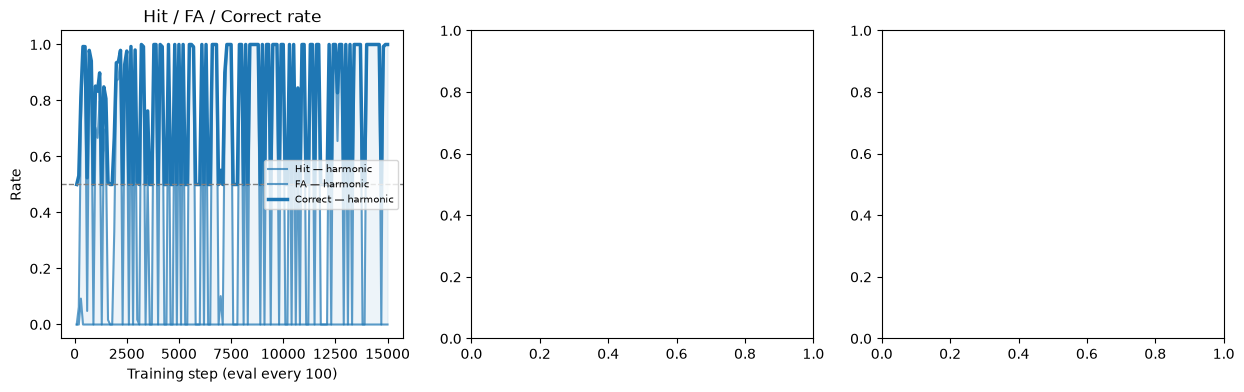

In [6]:
plot_training_log(log, cfg, title='Harmonic Complex Tone task')